In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("Bibliotheken erfolgreich importiert.")
# env variables
DB_USER = os.getenv("POSTGRES_USER", "admin")
DB_PASSWORD = os.getenv("POSTGRES_PASSWORD")

# test config password
if not DB_PASSWORD:
    raise ValueError(
        "POSTGRES_PASSWORD ist nicht konfiguriert. "
        "überprüfen Sie env variables ."
    )

# build conection secure
url = URL.create(
    drivername="postgresql+psycopg",
    username=DB_USER,
    password=DB_PASSWORD,
    host="city_move",
    port=5432,
    database=os.getenv("CITYMOVE_DB", "city_move"),
)

# engine on
engine = create_engine(url)

# test conection
with engine.connect() as connection:
    result = connection.execute(text("SELECT version()"))
    print("Erfolgreich.")
    print(result.scalar())


Bibliotheken erfolgreich importiert.
Erfolgreich.
PostgreSQL 18.6 (Debian 18.6-1.pgdg13+2) on x86_64-pc-linux-gnu, compiled by gcc (Debian 14.2.0-19) 14.2.0, 64-bit


In [9]:
# Fahrplandaten aus PostgreSQL laden.

query_fahrplan = """
SELECT
    id,
    id_fahrt,
    id_haltestelle,
    ankunft_geplant,
    abfahrt_geplant
FROM citymove.fahrplan;
"""

df_fahrplan = pd.read_sql(query_fahrplan, engine)

# Fahrgastzahlen aus PostgreSQL laden.

query_fahrgast = """
SELECT
    id,
    id_fahrt,
    id_haltestelle,
    einsteiger,
    aussteiger
FROM citymove.fahrgastaufkommen;
"""

df_fahrgast = pd.read_sql(query_fahrgast, engine)

# Haltestelleninformationen laden.

query_haltestellen = """
SELECT
    id,
    name,
    stadtteil,
    latitude,
    longitude
FROM citymove.haltestelle;
"""

df_haltestellen = pd.read_sql(query_haltestellen, engine)

# Anzahl der geladenen Datensätze überprüfen.

print("Fahrplandaten:", df_fahrplan.shape)
print("Fahrgastdaten:", df_fahrgast.shape)
print("Haltestellen:", df_haltestellen.shape)

Fahrplandaten: (2903, 5)
Fahrgastdaten: (2065, 5)
Haltestellen: (40, 5)


In [10]:
# Erste Datensätze anzeigen, um die Datenstruktur zu verstehen.

display(df_fahrplan.head())
display(df_fahrgast.head())
display(df_haltestellen.head())

# Datentypen und fehlende Werte untersuchen.

print("Datentypen im Fahrplan:")
print(df_fahrplan.dtypes)

print("\nFehlende Werte im Fahrplan:")
print(df_fahrplan.isna().sum())

print("\nFehlende Werte bei den Fahrgastzahlen:")
print(df_fahrgast.isna().sum())

,id,id_fahrt,id_haltestelle,ankunft_geplant,abfahrt_geplant
0,1,1,20,2026-06-29 14:15:00,2026-06-29 14:15:00
1,2,1,14,2026-06-29 14:21:00,2026-06-29 14:22:00
2,3,1,1,2026-06-29 14:24:00,2026-06-29 14:26:00
3,4,1,9,2026-06-29 14:30:00,2026-06-29 14:31:00
4,5,1,2,2026-06-29 14:35:00,2026-06-29 14:36:00


,id,id_fahrt,id_haltestelle,einsteiger,aussteiger
0,1,1,20,19,0
1,2,1,14,17,14
2,3,1,1,20,10
3,4,1,9,20,5
4,5,1,2,8,19


,id,name,stadtteil,latitude,longitude
0,1,Haltestelle Plauen 1,Plauen,51.029716,13.705512
1,2,Haltestelle Cotta 2,Cotta,51.048765,13.681174
2,3,Haltestelle Klotzsche 3,Klotzsche,51.112600,13.798638
3,4,Haltestelle Loschwitz 4,Loschwitz,51.060621,13.802437
4,5,Haltestelle Plauen 5,Plauen,51.014523,13.706747


Datentypen im Fahrplan:
id                          int64
id_fahrt                    int64
id_haltestelle              int64
ankunft_geplant    datetime64[us]
abfahrt_geplant    datetime64[us]
dtype: object

Fehlende Werte im Fahrplan:
id                 0
id_fahrt           0
id_haltestelle     0
ankunft_geplant    0
abfahrt_geplant    0
dtype: int64

Fehlende Werte bei den Fahrgastzahlen:
id                0
id_fahrt          0
id_haltestelle    0
einsteiger        0
aussteiger        0
dtype: int64


In [11]:
# Geplante und tatsächliche Ankunftszeiten zusammenführen.

query_verspaetung = """
SELECT
    f.id AS fahrt_id,
    f.datum,
    f.id_linie,
    f.fahrtrichtung,
    fh.id_haltestelle,
    fp.ankunft_geplant,
    fh.ankunft_tatsaechlich
FROM citymove.fahrt_haltestelle AS fh
JOIN citymove.fahrplan AS fp
    ON fp.id_fahrt = fh.id_fahrt
    AND fp.id_haltestelle = fh.id_haltestelle
JOIN citymove.fahrt AS f
    ON f.id = fh.id_fahrt
WHERE fp.ankunft_geplant IS NOT NULL
  AND fh.ankunft_tatsaechlich IS NOT NULL;
"""

df_verspaetung = pd.read_sql(query_verspaetung, engine)

print("Anzahl der Datensätze:", len(df_verspaetung))
display(df_verspaetung.head())

Anzahl der Datensätze: 2065


,fahrt_id,datum,id_linie,fahrtrichtung,id_haltestelle,ankunft_geplant,ankunft_tatsaechlich
0,1,2026-06-29,10,Rückfahrt,20,2026-06-29 14:15:00,2026-06-29 14:18:00
1,1,2026-06-29,10,Rückfahrt,14,2026-06-29 14:21:00,2026-06-29 14:21:00
2,1,2026-06-29,10,Rückfahrt,1,2026-06-29 14:24:00,2026-06-29 14:24:00
3,1,2026-06-29,10,Rückfahrt,9,2026-06-29 14:30:00,2026-06-29 14:38:00
4,1,2026-06-29,10,Rückfahrt,2,2026-06-29 14:35:00,2026-06-29 14:37:00


In [12]:
# Zeitstempel in datetime-Objekte umwandeln.

df_verspaetung["ankunft_geplant"] = pd.to_datetime(
    df_verspaetung["ankunft_geplant"],
    errors="coerce"
)

df_verspaetung["ankunft_tatsaechlich"] = pd.to_datetime(
    df_verspaetung["ankunft_tatsaechlich"],
    errors="coerce"
)

# Verspätung in Minuten berechnen.
# Positive Werte bedeuten Verspätung, negative Werte eine frühere Ankunft.

df_verspaetung["verspaetung_min"] = (
    df_verspaetung["ankunft_tatsaechlich"]
    - df_verspaetung["ankunft_geplant"]
).dt.total_seconds() / 60

# Fehlende Werte und mögliche ungültige Datensätze entfernen.

df_verspaetung = df_verspaetung.dropna(
    subset=[
        "verspaetung_min",
        "ankunft_geplant",
        "datum",
        "id_linie",
        "id_haltestelle"
    ]
)

print("Anzahl gültiger Datensätze:", len(df_verspaetung))
display(df_verspaetung[[
    "ankunft_geplant",
    "ankunft_tatsaechlich",
    "verspaetung_min"
]].head())

Anzahl gültiger Datensätze: 2065


,ankunft_geplant,ankunft_tatsaechlich,verspaetung_min
0,2026-06-29 14:15:00,2026-06-29 14:18:00,3.0
1,2026-06-29 14:21:00,2026-06-29 14:21:00,0.0
2,2026-06-29 14:24:00,2026-06-29 14:24:00,0.0
3,2026-06-29 14:30:00,2026-06-29 14:38:00,8.0
4,2026-06-29 14:35:00,2026-06-29 14:37:00,2.0


In [17]:
# Zeitmerkmale aus der geplanten Ankunft ableiten.

df_verspaetung["uhrzeit_stunde"] = (
    df_verspaetung["ankunft_geplant"].dt.hour
)

df_verspaetung["wochentag"] = (
    df_verspaetung["ankunft_geplant"].dt.dayofweek
)

# Zielvariable festlegen.
y = df_verspaetung["verspaetung_min"]

# Eingangsmerkmale auswählen.
# Tatsächliche Ankunftszeit und Verspätung werden nicht als Features verwendet.

X = df_verspaetung[[
    "id_linie",
    "id_haltestelle",
    "uhrzeit_stunde",
    "wochentag"
]]

# Fehlende Werte entfernen und die Zeilen synchron halten.

model_data = pd.concat([X, y.rename("verspaetung_min")], axis=1)
model_data = model_data.replace([np.inf, -np.inf], np.nan).dropna()

X = model_data.drop(columns="verspaetung_min")
y = model_data["verspaetung_min"]

print("Anzahl der Features:", X.shape[1])
print("Anzahl der Beobachtungen:", len(X))

Anzahl der Features: 4
Anzahl der Beobachtungen: 2065


In [29]:

# Trainings- und Testdaten aufteilen.
# 80 % der Daten werden zum Training und 20 % zum Testen verwendet.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Decision-Tree-Regressionsmodell erstellen.
tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

# Modell mit den Trainingsdaten trainieren.
tree_model.fit(X_train, y_train)

# Vorhersagen für die Testdaten berechnen.
y_pred = tree_model.predict(X_test)

# Modellgüte anhand verschiedener Kennzahlen bewerten.
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Ergebnisse ausgeben.
print(f"MAE:  {mae:.2f} Minuten")
print(f"RMSE: {rmse:.2f} Minuten")
print(f"R²:   {r2:.3f}")


MAE:  3.17 Minuten
RMSE: 4.53 Minuten
R²:   -0.110


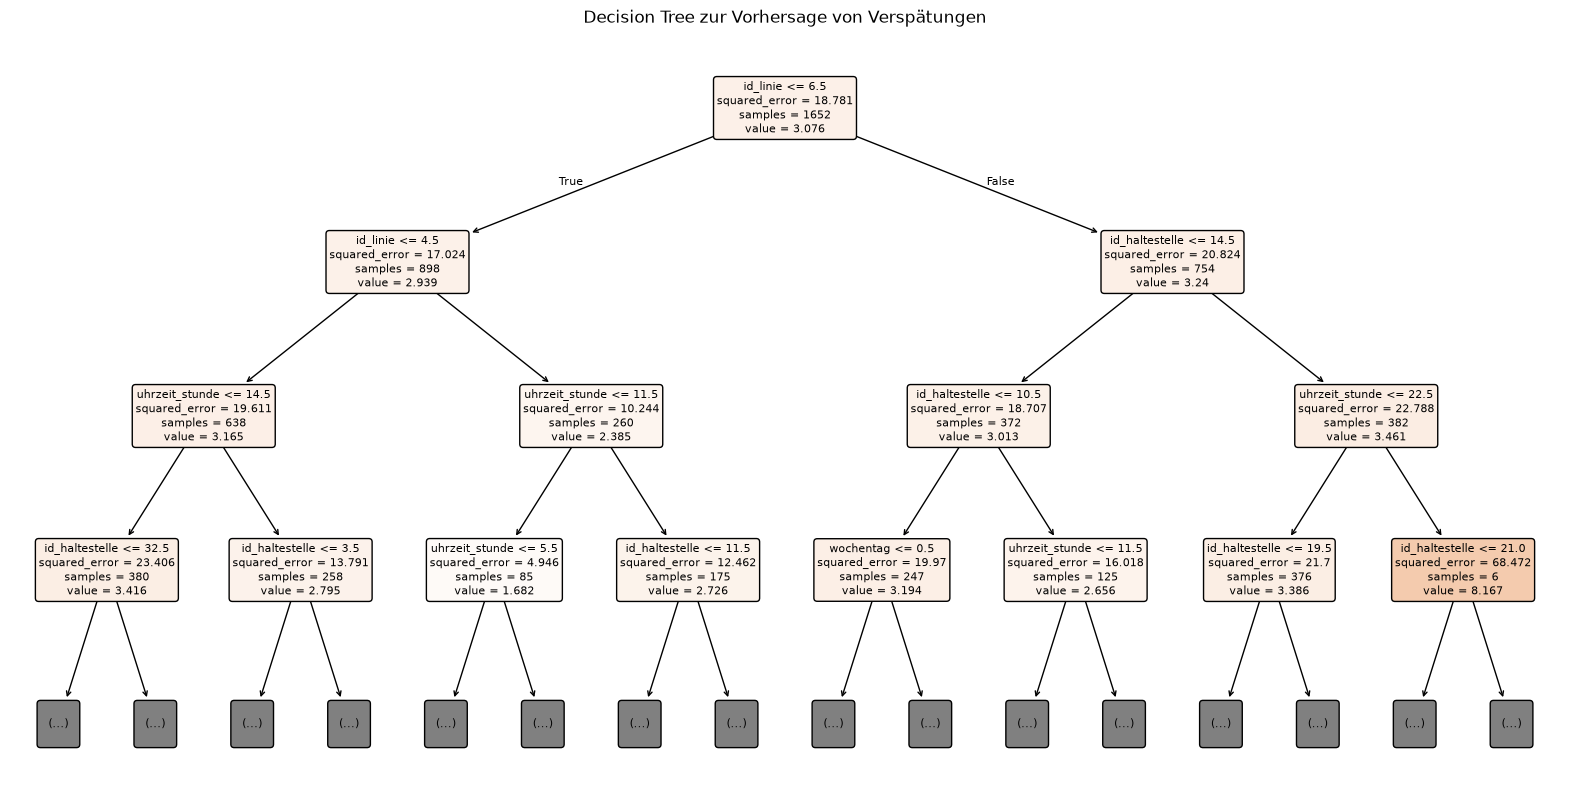

In [30]:
# Entscheidungsbaum grafisch darstellen.

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree zur Vorhersage von Verspätungen")
plt.show()

In [31]:
# Fahrgastzahlen nach Haltestelle aggregieren.

df_clusters = (
    df_fahrgast
    .groupby("id_haltestelle", as_index=False)
    .agg(
        einsteiger_gesamt=("einsteiger", "sum"),
        aussteiger_gesamt=("aussteiger", "sum"),
        anzahl_beobachtungen=("id", "count")
    )
)

# Haltestellennamen ergänzen.

df_clusters = df_clusters.merge(
    df_haltestellen[["id", "name", "stadtteil"]],
    left_on="id_haltestelle",
    right_on="id",
    how="left"
)

# Datensätze mit fehlenden oder ungültigen Werten entfernen.

features_cluster = [
    "einsteiger_gesamt",
    "aussteiger_gesamt"
]

df_clusters[features_cluster] = df_clusters[features_cluster].replace(
    [np.inf, -np.inf],
    np.nan
)

df_clusters = df_clusters.dropna(subset=features_cluster)

# Negative Fahrgastzahlen sind für diese Analyse nicht sinnvoll.
df_clusters = df_clusters[
    (df_clusters["einsteiger_gesamt"] >= 0)
    & (df_clusters["aussteiger_gesamt"] >= 0)
].copy()

print("Anzahl der Haltestellen:", len(df_clusters))
display(df_clusters.head())

Anzahl der Haltestellen: 36


,id_haltestelle,einsteiger_gesamt,aussteiger_gesamt,anzahl_beobachtungen,id,name,stadtteil
0,1,502,530,64,1,Haltestelle Plauen 1,Plauen
1,2,591,587,60,2,Haltestelle Cotta 2,Cotta
2,3,754,616,77,3,Haltestelle Klotzsche 3,Klotzsche
3,4,602,525,64,4,Haltestelle Loschwitz 4,Loschwitz
4,5,458,508,49,5,Haltestelle Plauen 5,Plauen


In [32]:
# Merkmale für das Clustering auswählen.

X_cluster = df_clusters[[
    "einsteiger_gesamt",
    "aussteiger_gesamt"
]]

# Merkmale auf eine vergleichbare Skala bringen.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Standardisierung abgeschlossen.")

Standardisierung abgeschlossen.


In [33]:
# Prüfen, ob genügend Haltestellen für drei Cluster vorhanden sind.

if len(df_clusters) < 3:
    raise ValueError(
        "Für diese Demonstration werden mindestens drei Haltestellen benötigt."
    )

# K-Means mit drei Clustern trainieren.

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df_clusters["cluster"] = kmeans.fit_predict(X_scaled)

# Anzahl der Haltestellen pro Cluster anzeigen.

print(df_clusters["cluster"].value_counts().sort_index())

display(
    df_clusters[[
        "name",
        "stadtteil",
        "einsteiger_gesamt",
        "aussteiger_gesamt",
        "cluster"
    ]].head(10)
)

cluster
0     7
1    15
2    14
Name: count, dtype: int64


,name,stadtteil,einsteiger_gesamt,aussteiger_gesamt,cluster
0,Haltestelle Plauen 1,Plauen,502,530,2
1,Haltestelle Cotta 2,Cotta,591,587,1
2,Haltestelle Klotzsche 3,Klotzsche,754,616,1
3,Haltestelle Loschwitz 4,Loschwitz,602,525,2
4,Haltestelle Plauen 5,Plauen,458,508,2
5,Haltestelle Innere Neustadt 6,Innere Neustadt,485,345,2
6,Haltestelle Klotzsche 8,Klotzsche,663,747,1
7,Haltestelle Leuben 9,Leuben,391,355,2
8,Haltestelle Plauen 10,Plauen,727,750,1
9,Haltestelle Äußere Neustadt 11,Äußere Neustadt,632,716,1


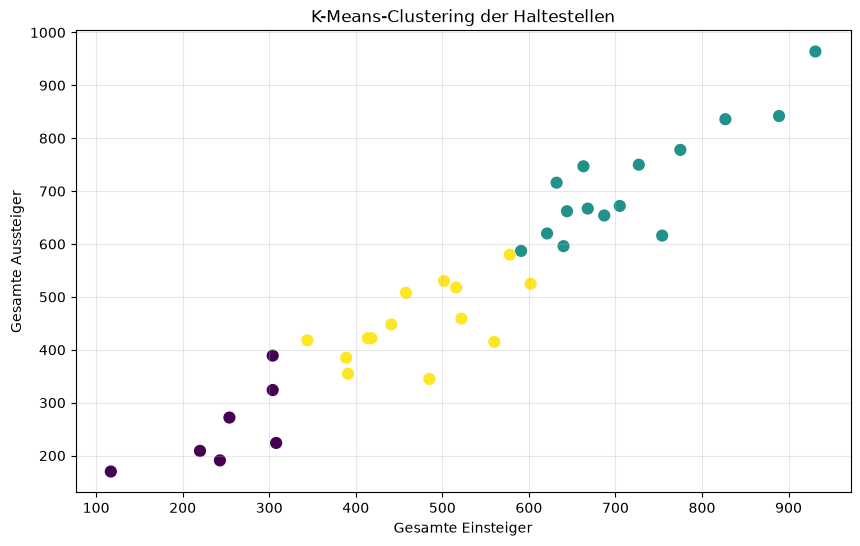

In [34]:
# Cluster in einem Streudiagramm darstellen.

plt.figure(figsize=(10, 6))

plt.scatter(
    df_clusters["einsteiger_gesamt"],
    df_clusters["aussteiger_gesamt"],
    c=df_clusters["cluster"],
    s=60
)

plt.xlabel("Gesamte Einsteiger")
plt.ylabel("Gesamte Aussteiger")
plt.title("K-Means-Clustering der Haltestellen")
plt.grid(True, alpha=0.3)
plt.show()

In [35]:
# Durchschnittliches Fahrgastaufkommen pro Cluster analysieren.

cluster_summary = (
    df_clusters
    .groupby("cluster")
    .agg(
        anzahl_haltestellen=("id_haltestelle", "count"),
        durchschnitt_einsteiger=("einsteiger_gesamt", "mean"),
        durchschnitt_aussteiger=("aussteiger_gesamt", "mean")
    )
    .round(2)
)

display(cluster_summary)

,anzahl_haltestellen,durchschnitt_einsteiger,durchschnitt_aussteiger
cluster,,,
0,7,250.00,254.14
1,15,716.93,713.80
2,14,472.86,452.14


In [36]:
# Silhouette Score nur berechnen, wenn mehr als ein Cluster
# und weniger Cluster als Datenpunkte vorhanden sind.

labels = df_clusters["cluster"]

if 1 < labels.nunique() < len(df_clusters):
    score = silhouette_score(X_scaled, labels)
    print(f"Silhouette Score: {score:.3f}")
else:
    print("Silhouette Score kann für diese Clusterstruktur nicht berechnet werden.")

Silhouette Score: 0.480
